# Diagnóstico de cancro da mama — Active Learning com Human-in-the-Loop

**Inteligência Artificial Centrada no Humano** · Mestrado em Inteligência Artificial e Engenharia de Dados · FCTUC

Compara estratégias de Active Learning com a escolha **ao acaso**, para ver se escolher bem que imagens anotar poupa trabalho ao médico.

## O que é Active Learning?

Anotar ecografias exige um médico e é caro e demorado. No **Passive Learning** (notebook 01), o modelo recebe todas as imagens já anotadas. No **Active Learning**, começa com poucas imagens anotadas e é o próprio modelo que escolhe quais quer ver anotadas a seguir: as que lhe trazem mais informação, normalmente aquelas em que está mais indeciso. O objetivo é chegar a um desempenho parecido com o de ter tudo anotado, com muito menos anotações.

### O ciclo, passo a passo
1. Treinar o modelo com um pequeno conjunto inicial de imagens anotadas (`N_INITIAL`).
2. As restantes imagens de treino formam a **pool** (imagens "sem label").
3. Em cada iteração:
   - o modelo calcula as probabilidades para todas as imagens da pool e, com uma **estratégia de query**, escolhe as `N_INSTANCES` mais úteis;
   - o **humano** dá a classe correta dessas imagens (*Human-in-the-Loop*, secção 6);
   - as imagens passam da pool para o conjunto anotado e o modelo volta a treinar;
   - mede-se o desempenho no conjunto de teste.
4. Repetir durante `N_QUERIES` iterações.

### As estratégias de query (biblioteca [modAL](https://modal-python.readthedocs.io/))
O modelo dá 3 probabilidades por imagem, por exemplo `[0.40, 0.35, 0.25]`. As estratégias medem a "indecisão" de formas diferentes:

| Estratégia | Escolhe as imagens com… | No exemplo |
|---|---|---|
| `uncertainty` | maior incerteza = 1 − probabilidade da classe mais provável | 1 − 0.40 = 0.60 |
| `margin` | menor diferença entre as duas classes mais prováveis | 0.40 − 0.35 = 0.05 |
| `malignant` (nossa) | probabilidade de **maligno** mais perto de 0.5 (o modelo não sabe se é cancro ou não) | — |
| `random` | escolha ao acaso, **sem** olhar para o modelo | — |

A estratégia `malignant` não vem do modAL: escrevemo-la nós (`malignant_sampling` em `src/active_learning.py`). As outras duas tratam as 3 classes por igual, por isso podem gastar anotações em imagens indecisas entre normal e benigno, que não interessam para detetar cancro. A `malignant` só olha para a pergunta que importa ao projeto: *é maligno ou não?*

`random` é o que se faria sem Active Learning (anotar imagens quaisquer), por isso é a referência.

### Como desenhámos as experiências (e porquê)
Para o Active Learning mostrar alguma coisa, o modelo tem de começar com **poucas** imagens anotadas e pedir bastantes ao longo do ciclo: se começasse com 1000 imagens anotadas e pedisse só mais 10, passar de 1000 para 1010 quase não mudaria nada. Numa primeira versão, treinávamos a CNN inteira em cada iteração: cada treino demorava vários minutos e o processo acabou morto por falta de RAM.

Por isso:
- começamos com **20** imagens anotadas e pedimos **10 por iteração** durante **25 iterações** (até 270 imagens, cerca de 70% da pool);
- a pool tem só as **imagens originais**, sem as cópias rodadas, e **uma só imagem de cada ecografia repetida**: o humano anota imagens reais, e anotar outra vez a mesma ecografia (rodada ou noutro ficheiro) seria trabalho deitado fora;
- o conjunto inicial é escolhido ao acaso mas **estratificado**, para ter sempre imagens das 3 classes, e é o **mesmo** para todas as estratégias com a mesma seed, para a comparação ser justa;
- o modelo é um classificador simples sobre features da MobileNetV2 (secção 3), que treina em milissegundos. Assim podemos repetir tudo com **20 seeds** (com 5, a ordem das estratégias mudava de uma corrida para a outra: as diferenças entre elas são pequenas).

## 1. Configuração

Igual ao notebook 01: importa `src/`, lê os caminhos e prepara a GPU (usada só para extrair as features da secção 3).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent   # raiz do repositório (o notebook está em notebooks/)
sys.path.insert(0, str(ROOT))

from src.config import DATA_PATH, RESULTS_PATH
from src.gpu import setup_gpu

setup_gpu()

A treinar na GPU: NVIDIA GeForce RTX 3050 Laptop GPU


True

### Parâmetros
- **`N_INITIAL`**, **`N_INSTANCES`**, **`N_QUERIES`**: imagens anotadas no início, pedidas por iteração e nº de iterações. No fim há `N_INITIAL + N_INSTANCES × N_QUERIES` = 270 imagens anotadas.
- **`SEEDS`**: 20 conjuntos iniciais diferentes.
- **`HUMAN`**: ver a secção 6.

In [2]:
# Parâmetros
IMG_SIZE = 128
STRATEGIES = ["random", "uncertainty", "margin", "malignant"]
N_INITIAL = 20          # imagens anotadas no início
N_INSTANCES = 10        # imagens pedidas ao humano por iteração
N_QUERIES = 25          # nº de iterações
SEEDS = list(range(20))
HUMAN = False           # True: pede a label a uma pessoa; False: simula o humano com a label do dataset

## 2. Dados

A mesma divisão do notebook 01 (mesma seed, por isso as mesmas imagens de teste), com `balance=False` (sem cópias rodadas) e `unique_train=True` (uma imagem por ecografia): a pool fica com **381 imagens**. O desequilíbrio entre classes é compensado no classificador (`class_weight="balanced"`), não com cópias.

In [3]:
import numpy as np
from src.data import CLASSES, load_dataset, summarize

x_train, x_val, x_test, y_train, y_val, y_test = load_dataset(DATA_PATH, size=IMG_SIZE, balance=False, unique_train=True)
summarize(x_train, x_val, x_test, y_train, y_val, y_test)

Treino: (381, 128, 128), validação: (127, 128, 128), teste: (149, 128, 128)
Memória das imagens: 43 MB
Treino: {'normal': 61, 'benign': 202, 'malignant': 118}
Validação: {'normal': 21, 'benign': 69, 'malignant': 37}
Teste: {'normal': 28, 'benign': 82, 'malignant': 39}


## 3. Features da MobileNetV2

Em vez de treinar uma CNN inteira em cada iteração, cada imagem passa **uma única vez** pela MobileNetV2 pré-treinada (sem a camada de saída) e é transformada num vetor de **1280 números** (*features*) que resume o seu conteúdo: texturas, contornos, formas. É a mesma rede que deu o melhor resultado no notebook 01.

Depois, o Active Learning treina só um classificador simples sobre esses vetores: uma **regressão logística** (`make_classifier` em `src/active_learning.py`), que aprende um peso por feature e por classe. É o equivalente a treinar só a última camada da rede, como na fase 1 do notebook 01.

**Regularização (`C`).** A regressão logística tem um parâmetro `C`: quanto menor, mais simples o modelo e menos risco de *overfitting*. Escolhemos `C` com o **conjunto de validação**, treinando com toda a pool. O teste não é usado para esta escolha.

In [4]:
from src.model import extract_features

f_train, f_val, f_test = extract_features(x_train, x_val, x_test)
print("Features:", f_train.shape, f_val.shape, f_test.shape)

Features: (381, 1280) (127, 1280) (149, 1280)


In [5]:
from src.active_learning import make_classifier
from src.evaluation import compute_metrics

val_accuracy = {}
for C in [0.001, 0.01, 0.1, 1.0]:
    clf = make_classifier(C).fit(f_train, y_train)
    val_accuracy[C] = float(np.mean(clf.predict(f_val) == y_val))
    print(f"C = {C:<6} accuracy de validação = {val_accuracy[C]:.3f}")
C = max(val_accuracy, key=val_accuracy.get)
print("C escolhido:", C)

# Referência: o mesmo classificador treinado com TODA a pool anotada
full = compute_metrics(y_test, make_classifier(C).fit(f_train, y_train).predict(f_test))
full

C = 0.001  accuracy de validação = 0.732
C = 0.01   accuracy de validação = 0.756
C = 0.1    accuracy de validação = 0.748


C = 1.0    accuracy de validação = 0.732
C escolhido: 0.01


{'accuracy': 0.785234899328859,
 'recall_malignant': 0.717948717948718,
 'false_negatives': 11}

## 4. Experiências

Para cada estratégia e cada seed, `run_active_learning` corre o ciclo completo e regista as métricas no teste depois de cada iteração: 4 estratégias × 20 seeds = 80 experiências de cerca de um segundo cada. Os resultados ficam em `results/active_learning.json`.

In [6]:
import time
from src.active_learning import run_active_learning
from src.evaluation import save_json

results = {strategy: [] for strategy in STRATEGIES}   # results[estratégia] = [history de cada seed]
start = time.time()
for strategy in STRATEGIES:
    for seed in SEEDS:
        results[strategy].append(run_active_learning(strategy, f_train, y_train, f_test, y_test, n_initial=N_INITIAL,
                                                     n_instances=N_INSTANCES, n_queries=N_QUERIES, C=C, seed=seed))
print(f"Tempo total: {time.time() - start:.0f} s")

save_json({"params": {"img_size": IMG_SIZE, "n_initial": N_INITIAL, "n_instances": N_INSTANCES,
                      "n_queries": N_QUERIES, "seeds": SEEDS, "C": C},
           "full_pool": full, "results": results}, RESULTS_PATH / "active_learning.json")

Tempo total: 55 s


## 5. Resultados

### 5.1 Curvas de aprendizagem
Cada linha mostra o desempenho no teste em função do **nº de imagens anotadas**: a média das 20 seeds, com a sombra a mostrar ± 1 desvio padrão. A linha pontilhada preta é o resultado com a pool toda anotada.

**Como ler:** uma estratégia é melhor do que `random` (cinzento tracejado) se a sua curva estiver **acima**, ou seja, se para o mesmo nº de anotações tiver melhor desempenho, ou se chegar ao mesmo desempenho com menos anotações.

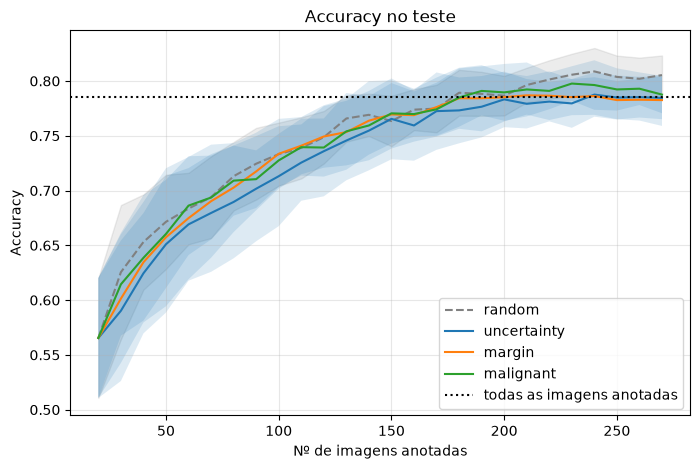

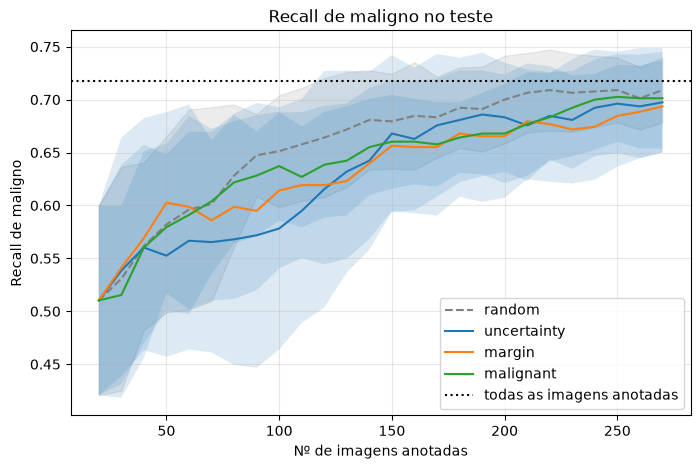

In [7]:
from src.evaluation import plot_learning_curves

plot_learning_curves(results, "accuracy", "Accuracy no teste", reference=full["accuracy"], ylabel="Accuracy")
plot_learning_curves(results, "recall_malignant", "Recall de maligno no teste", reference=full["recall_malignant"],
                     ylabel="Recall de maligno")

### 5.2 Tabelas
Accuracy e recall de maligno (média ± desvio padrão das 20 seeds) para alguns nºs de imagens anotadas.

Depois, para comparar cada estratégia com `random` de forma simples: em cada seed calcula-se a média da métrica ao longo de toda a curva (das 20 às 270 imagens), e conta-se em quantas das 20 seeds `random` ficou acima. Como todas as estratégias começam com as mesmas 20 imagens em cada seed, a comparação é justa. Se fosse por acaso, `random` ganharia em cerca de metade (10 de 20).

In [8]:
checkpoints = [50, 100, 150, 200, 270]
n_labeled = np.array(results["random"][0]["n_labeled"])

def table(metric, title):
    print(title)
    print(f"{'estratégia':<13}" + "".join(f"{n:>14}" for n in checkpoints))
    for strategy in STRATEGIES:
        values = np.array([run[metric] for run in results[strategy]])
        mean, std = values.mean(axis=0), values.std(axis=0)
        print(f"{strategy:<13}" + "".join(f"{mean[n_labeled == n][0]:>8.3f} ± {std[n_labeled == n][0]:.2f}" for n in checkpoints))
    print()

def curve_average(strategy, metric):
    """Média da métrica ao longo de toda a curva, uma por seed."""
    return np.array([np.mean(run[metric]) for run in results[strategy]])

table("accuracy", f"Accuracy (média ± desvio padrão de {len(SEEDS)} seeds)")
table("recall_malignant", "Recall de maligno")

print(f"Em quantas das {len(SEEDS)} seeds random ficou acima (média da curva toda):")
for strategy in STRATEGIES[1:]:
    wins = {m: int(np.sum(curve_average("random", m) > curve_average(strategy, m))) for m in ["accuracy", "recall_malignant"]}
    print(f"  {strategy:<12} accuracy: {wins['accuracy']:>2} de {len(SEEDS)}   recall de maligno: {wins['recall_malignant']:>2} de {len(SEEDS)}")

Accuracy (média ± desvio padrão de 20 seeds)
estratégia               50           100           150           200           270
random          0.671 ± 0.04   0.733 ± 0.03   0.763 ± 0.02   0.787 ± 0.02   0.805 ± 0.02
uncertainty     0.651 ± 0.06   0.713 ± 0.05   0.765 ± 0.04   0.783 ± 0.03   0.785 ± 0.02
margin          0.657 ± 0.06   0.734 ± 0.03   0.769 ± 0.03   0.785 ± 0.02   0.783 ± 0.02
malignant       0.660 ± 0.05   0.728 ± 0.02   0.770 ± 0.03   0.790 ± 0.03   0.788 ± 0.02

Recall de maligno
estratégia               50           100           150           200           270
random          0.582 ± 0.08   0.651 ± 0.05   0.679 ± 0.04   0.700 ± 0.04   0.709 ± 0.03
uncertainty     0.553 ± 0.10   0.578 ± 0.11   0.668 ± 0.07   0.683 ± 0.05   0.697 ± 0.05
margin          0.603 ± 0.09   0.614 ± 0.07   0.656 ± 0.06   0.665 ± 0.06   0.694 ± 0.04
malignant       0.579 ± 0.08   0.637 ± 0.05   0.660 ± 0.04   0.668 ± 0.05   0.701 ± 0.05

Em quantas das 20 seeds random ficou acima (média da cu

### 5.3 Que imagens escolhe cada estratégia?
Distribuição das classes nas imagens pedidas ao humano (todas as seeds juntas), comparada com a distribuição da pool. `random` segue as proporções da pool; as outras estratégias não.

In [9]:
print(f"{'pool':<13}", {name: f"{np.mean(y_train == i):.0%}" for i, name in enumerate(CLASSES)})
for strategy in STRATEGIES:
    queried = np.concatenate([y_train[run["queried"]] for run in results[strategy]])
    shares = {name: f"{np.mean(queried == i):.0%}" for i, name in enumerate(CLASSES)}
    print(f"{strategy:<13}", shares)

pool          {'normal': '16%', 'benign': '53%', 'malignant': '31%'}
random        {'normal': '16%', 'benign': '53%', 'malignant': '30%'}
uncertainty   {'normal': '21%', 'benign': '48%', 'malignant': '32%'}
margin        {'normal': '20%', 'benign': '48%', 'malignant': '32%'}
malignant     {'normal': '15%', 'benign': '47%', 'malignant': '38%'}


## 6. Humano no ciclo

Com `HUMAN = True` (nos parâmetros), esta célula corre um ciclo curto com a estratégia `margin`: em cada iteração aparecem as imagens escolhidas, com a sugestão do modelo, e é preciso escrever a classe (0, 1 ou 2). **O modelo aprende com a resposta da pessoa, mesmo que esteja errada.** Com `HUMAN = False` não faz nada, e nas experiências da secção 4 a resposta do humano é simulada com a label verdadeira do dataset, para se poder correr tudo sem ninguém ao teclado.

In [10]:
if HUMAN:
    human_run = run_active_learning("margin", f_train, y_train, f_test, y_test, n_initial=N_INITIAL, n_instances=3,
                                    n_queries=2, C=C, seed=0, human=True, images=x_train)
    print("Accuracy no teste depois de cada iteração:", [round(v, 3) for v in human_run["accuracy"]])

## 7. Conclusões

**Referência:** o mesmo classificador (regressão logística sobre as features da MobileNetV2) treinado com a pool toda anotada (381 imagens) tem accuracy 0.79 e recall de maligno 0.72, perto da MobileNetV2 com fine-tuning do notebook 01 (0.80), com um modelo que treina em milissegundos.

1. **O Active Learning não poupa anotações em relação à escolha ao acaso.** Na accuracy, `margin` e `malignant` ficam ao nível de `random` até às ~200 imagens (no máximo 0.7 pontos acima), muito menos do que o desvio padrão entre seeds (0.02–0.06). Com 270 imagens, `random` é a melhor (0.805, contra 0.783–0.788). Na média da curva toda, `random` fica acima de `uncertainty` em 16 das 20 seeds e de `margin` e `malignant` em 14.
2. **As estratégias de incerteza detetam um pouco menos cancros do que `random`.** A partir das 70 imagens anotadas, o recall de maligno de `random` é quase sempre igual ou superior ao das outras estratégias (com 100 imagens, 65% contra 58% em `uncertainty`); só `margin` fica um pouco acima nas primeiras 60. No fim (270), ficam todas perto de 0.70. Na média da curva toda, `random` deteta mais cancros em 12 ou 13 das 20 seeds: perto das 10 que daria o acaso, por isso esta diferença é pequena.
3. **A estratégia `malignant` pede mais imagens malignas ao humano** (38%, contra 31% na pool), mas isso não se traduz em melhor recall de maligno.
4. **O que mudou ao corrigir o leakage.** Com a divisão antiga (com ecografias repetidas entre treino e teste), as estratégias pareciam poupar ~24% das anotações. Com a divisão por grupos e uma só imagem por ecografia na pool, essa vantagem desaparece. Também testámos (fora do notebook) pedir uma imagem de cada vez e a estratégia do modAL que combina incerteza com diversidade (`uncertainty_batch_sampling`): os resultados ficaram sempre perto de `random`.
5. **Porque é que o Active Learning não ajuda aqui?** Hipóteses (não provadas): (a) as features da MobileNetV2 já separam bem as classes, por isso qualquer amostra ao acaso é informativa; (b) as imagens "mais indecisas" são muitas vezes as mais ambíguas ou com labels duvidosas (o dataset tem labels contraditórias, ver o notebook 00), e ensinar o modelo com elas não ajuda; (c) com só ~380 imagens na pool, há pouco por onde escolher.
6. **Lição para o Human-in-the-Loop:** pedir ao humano as imagens em que o modelo está mais indeciso não garante poupar anotações nem detetar mais cancros. Num problema médico, é preciso comparar sempre com a escolha ao acaso e avaliar a classe que importa (maligno), e não só a accuracy média.